# PRACTICE 3 — GET STARTED WITH HUGGING FACE

**Nhóm 4 · Deep Learning · Phân loại cảm xúc IMDb bằng DistilBERT**

Notebook gồm ba phần theo thứ tự:

1. **Phần A:** Nạp IMDb → kiểm tra dữ liệu → trực quan hóa EDA → TF-IDF và PCA.
2. **Exercise 1:** Nạp mô hình sentiment pretrained → tokenize câu → dự đoán cảm xúc.
3. **Exercise 2:** Chia train/validation/test → tokenization → thiết lập `Trainer` → fine-tuning → đánh giá → lưu/nạp mô hình.

**Nguồn dữ liệu:** `stanfordnlp/imdb` trên Hugging Face Hub. Hai nhãn: `0 = NEGATIVE`, `1 = POSITIVE`.

Notebook **tự chạy độc lập**: không cần thư mục `src/`, `configs/` hay các CSV đã được tạo trước. Tất cả biểu đồ và kết quả mới được tạo từ dữ liệu trong lượt chạy hiện tại. Không dùng số liệu mô phỏng để thay cho kết quả huấn luyện.

> **Quan trọng:** Muốn có kết quả mới phải chạy các cell với Internet, thư viện đã cài và `RUN_TRAIN = True`. Trên CPU, fine-tuning có thể mất nhiều thời gian.

## A.1 — Chuẩn bị môi trường

**Bước cài thư viện (chỉ làm khi thiếu thư viện):** Trong **PowerShell** tại thư mục project, chạy:

```powershell
python -m pip install -U "transformers>=4.45,<5" "datasets>=3,<5" "accelerate>=0.26,<2" "evaluate>=0.4" scikit-learn matplotlib pandas numpy torch ipykernel
```

Hoặc mở một cell Jupyter riêng và chạy cùng lệnh với tiền tố `%pip install` (không dùng `%pip` trong PowerShell). **Restart Kernel** sau khi cài hoặc cập nhật.

Nếu gặp `Ignoring invalid distribution ~ip` hay `~ransformers`, đó là cảnh báo thư mục cài đặt cũ; nên tạo môi trường ảo sạch nếu tình trạng kéo dài.

Mỗi lần chạy từ đầu, sử dụng **Restart Kernel → Run All** để bảo đảm biến và dữ liệu ở đúng thứ tự.

In [1]:
# Các thư viện cơ bản cần cho EDA, thống kê và lưu kết quả.
import gc
import html
import importlib.util
import inspect
import json
import math
import platform
import re
import sys
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)
from sklearn.model_selection import train_test_split

# Không phụ thuộc vào tên/thư mục của notebook.
# Nếu đang chạy trong repo, ghi kết quả vào outputs/ của repo; nếu không thì ghi cạnh notebook.
PROJECT_ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "configs" / "default.json").is_file()),
    Path.cwd(),
)
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
OUTPUT_DIR = PROJECT_ROOT / "outputs" / f"practice3_{RUN_ID}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Hàm ghi JSON thống nhất, hỗ trợ tiếng Việt.
def save_json(path, data):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")

print("Python:", sys.version.split()[0], "| OS:", platform.system())
print("Working directory:", Path.cwd())
print("Kết quả mới sẽ lưu vào:", OUTPUT_DIR)

Python: 3.13.13 | OS: Windows
Working directory: c:\Users\Hoang Thien (Sora)\Downloads
Kết quả mới sẽ lưu vào: c:\Users\Hoang Thien (Sora)\Downloads\outputs\practice3_20261113_163141


## A.2 — Kiểm tra thư viện và cấu hình

Notebook mặc định chạy **1.000 train / 200 validation / 200 test**, 2 epoch, batch size 8. Đây là cấu hình thực hành, không phải toàn bộ 50.000 review IMDb. Dữ liệu test luôn lấy từ **test split gốc** và không dùng để chọn checkpoint.

- Đặt `QUICK_TEST = True` khi chỉ muốn kiểm tra luồng bằng tập nhỏ (**không dùng kết quả quick test để kết luận bài tập**).
- Đặt `RUN_TRAIN = False` nếu chỉ muốn chạy EDA + Exercise 1 + chuẩn bị dữ liệu mà chưa fine-tune.
- Chạy chế độ đầy đủ với `QUICK_TEST = False`, `RUN_TRAIN = True`.

Nếu project có `configs/default.json`, các tham số tương ứng sẽ được đọc từ đó (không sửa file gốc).

In [2]:
# Có thể thay đổi hai công tắc dưới đây trước khi chạy toàn bộ notebook.
QUICK_TEST = False  # True: 100 train, 40 validation, 40 test và 1 epoch.
RUN_TRAIN = True    # False: không tạo Trainer, không huấn luyện, không xuất metrics mới.

CONFIG = {
    "seed": 42,
    "dataset": "stanfordnlp/imdb",
    "model": "distilbert/distilbert-base-uncased",
    "exercise1_model": "distilbert/distilbert-base-uncased-finetuned-sst-2-english",
    "train_size": 1000,
    "validation_size": 200,
    "test_size": 200,
    "max_length": 256,
    "epochs": 2,
    "batch_size": 8,
    "learning_rate": 2e-5,
    "weight_decay": 0.01,
}
config_file = PROJECT_ROOT / "configs" / "default.json"
if config_file.is_file():
    project_config = json.loads(config_file.read_text(encoding="utf-8"))
    CONFIG.update({k: v for k, v in project_config.items() if k in CONFIG})
if QUICK_TEST:
    CONFIG.update(train_size=100, validation_size=40, test_size=40, epochs=1)

# Kiểm tra từ đầu để không phát sinh hàng loạt lỗi ở các cell sau.
required = ["torch", "transformers", "datasets", "sklearn", "pandas", "numpy", "matplotlib"]
if RUN_TRAIN:
    required.append("accelerate")
missing = [name for name in required if importlib.util.find_spec(name) is None]
for name in required:
    print(f"{name:13}: {'THIẾU' if name in missing else 'OK'}")
if missing:
    raise ModuleNotFoundError(
        "Thiếu: " + ", ".join(missing) + ". Cài theo mục A.1, Restart Kernel và chạy lại từ đầu."
    )

import torch
from transformers import set_seed
set_seed(int(CONFIG["seed"]))
print("GPU CUDA:", torch.cuda.is_available())
print("Cấu hình:", CONFIG)
save_json(OUTPUT_DIR / "config.json", {"config": CONFIG, "quick_test": QUICK_TEST,
                                      "run_train": RUN_TRAIN, "python": sys.version.split()[0]})

torch        : OK
transformers : OK
datasets     : OK
sklearn      : OK
pandas       : OK
numpy        : OK
matplotlib   : OK
accelerate   : OK


d:\lab\Lab3_DL_Group4-main\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU CUDA: False
Cấu hình: {'seed': 42, 'dataset': 'stanfordnlp/imdb', 'model': 'distilbert/distilbert-base-uncased', 'exercise1_model': 'distilbert/distilbert-base-uncased-finetuned-sst-2-english', 'train_size': 1000, 'validation_size': 200, 'test_size': 200, 'max_length': 256, 'epochs': 2, 'batch_size': 8, 'learning_rate': 2e-05, 'weight_decay': 0.01}


## A.3 — Nạp dữ liệu IMDb

Tải bằng `datasets.load_dataset` **một lần duy nhất**. IMDb có split `train` (25.000 review) và `test` (25.000 review). Hai split này được quản lý riêng, tránh đánh giá trên dữ liệu dùng để train.

Bước tải lần đầu cần Internet; các lần sau có thể dùng cache Hugging Face. Nếu bị lỗi kết nối, cần kiểm tra mạng thay vì chạy tiếp các cell sử dụng `raw`.

In [3]:
from datasets import Dataset, load_dataset

try:
    raw = load_dataset(CONFIG["dataset"])
except Exception as exc:
    raise RuntimeError(
        "Không tải được IMDb. Kiểm tra Internet, kết nối huggingface.co hoặc cache dữ liệu. "
        "Không tiếp tục khi chưa có dữ liệu thực."
    ) from exc

if not {"train", "test"}.issubset(raw.keys()):
    raise ValueError(f"IMDb không có đủ train/test split. Các split tìm thấy: {list(raw.keys())}")
raw_train_df = raw["train"].to_pandas()[["text", "label"]].copy()
raw_test_df = raw["test"].to_pandas()[["text", "label"]].copy()
print("Train gốc:", raw_train_df.shape, "| Test gốc:", raw_test_df.shape)
print("Phân phối train gốc:", raw_train_df["label"].value_counts().sort_index().to_dict())
display(raw_train_df.head(3).assign(text=lambda df: df["text"].str.slice(0, 140)))

Train gốc: (25000, 2) | Test gốc: (25000, 2)
Phân phối train gốc: {0: 12500, 1: 12500}


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0


## A.4 — Làm sạch và kiểm tra chất lượng dữ liệu

- Chuẩn hóa `<br />`, HTML entities và dấu cách thừa.
- Kiểm tra review thiếu/rỗng, trùng nội dung và trùng nội dung nhưng khác nhãn.
- Để tránh rò rỉ dữ liệu, loại bỏ văn bản lặp trong từng split và văn bản có nhãn mâu thuẫn.

Số lượng mẫu sau tiền xử lý phải được ghi lại: **không mặc định dữ liệu sạch có cùng kích thước dữ liệu gốc**.

In [4]:
def clean_text(value):
    """Chuẩn hóa HTML và khoảng trắng, không bỏ các từ thể hiện cảm xúc."""
    if pd.isna(value):
        return ""
    text = html.unescape(str(value))
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"<[^>]+>", " ", text)  # Chỉ bỏ các thẻ HTML còn lại.
    return re.sub(r"\s+", " ", text).strip()


def prepare_dataframe(source_df):
    df = source_df[["text", "label"]].copy()
    df["text"] = df["text"].map(clean_text)
    df["label"] = df["label"].astype(int)
    missing_or_empty = int(df["text"].eq("").sum())
    duplicates = int(df["text"].duplicated().sum())
    conflicts = df.groupby("text")["label"].nunique()
    conflicting_texts = set(conflicts[conflicts > 1].index)
    df = df.loc[df["text"].ne("") & ~df["text"].isin(conflicting_texts)]
    df = df.drop_duplicates(subset=["text"], keep="first").reset_index(drop=True)
    df["label_name"] = df["label"].map({0: "NEGATIVE", 1: "POSITIVE"})
    df["length_words"] = df["text"].str.split().str.len()
    info = {"rows_before": len(source_df), "empty_text": missing_or_empty,
            "duplicate_texts": duplicates, "conflicting_text_groups": len(conflicting_texts),
            "rows_after": len(df)}
    return df, info

train_df, train_quality = prepare_dataframe(raw_train_df)
test_df, test_quality = prepare_dataframe(raw_test_df)
print("Chất lượng train:", train_quality)
print("Chất lượng test:", test_quality)
assert set(train_df["label"].unique()) == {0, 1}
assert len(train_df) >= CONFIG["train_size"] + CONFIG["validation_size"]
save_json(OUTPUT_DIR / "eda_quality.json", {"train": train_quality, "test": test_quality})

display(train_df.groupby("label_name")["length_words"]
        .agg(["count", "mean", "median", "min", "max"]).round(2))

Chất lượng train: {'rows_before': 25000, 'empty_text': 0, 'duplicate_texts': 98, 'conflicting_text_groups': 0, 'rows_after': 24902}
Chất lượng test: {'rows_before': 25000, 'empty_text': 0, 'duplicate_texts': 201, 'conflicting_text_groups': 0, 'rows_after': 24799}


,count,mean,median,min,max
label_name,,,,,
NEGATIVE,12431,228.71,173.0,10,1491
POSITIVE,12471,234.71,173.0,12,2459


## A.5 — Trực quan hóa phân phối nhãn và độ dài review

Biểu đồ thứ nhất dùng kiểm tra mất cân bằng lớp; biểu đồ thứ hai cho biết độ dài văn bản và hỗ trợ lựa chọn ngưỡng `max_length=256` token (khác với số từ).

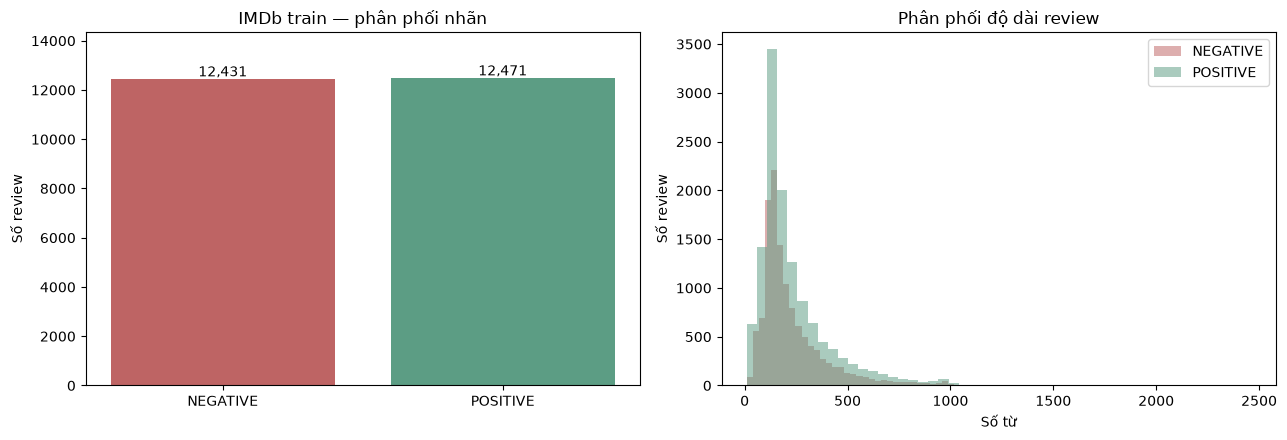

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = ["NEGATIVE", "POSITIVE"]
counts = train_df["label_name"].value_counts().reindex(order)
axes[0].bar(order, counts.values, color=["#be6464", "#5c9d84"])
for i, n in enumerate(counts.values):
    axes[0].text(i, n + max(counts) * .01, f"{n:,}", ha="center")
axes[0].set(title="IMDb train — phân phối nhãn", ylabel="Số review", ylim=(0, max(counts)*1.15))
for name, color in zip(order, ["#be6464", "#5c9d84"]):
    lengths = train_df.loc[train_df["label_name"].eq(name), "length_words"]
    axes[1].hist(lengths, bins=50, alpha=.52, label=name, color=color)
axes[1].legend()
axes[1].set(title="Phân phối độ dài review", xlabel="Số từ", ylabel="Số review")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "eda_class_length.png", dpi=160)
plt.show()

## A.6 — Khám phá dữ liệu bằng TF-IDF + PCA

PCA ở đây dùng **khám phá dữ liệu**, không phải thành phần của DistilBERT. Chọn tối đa 500 review mỗi lớp, trích xuất 1.000 đặc trưng TF-IDF và chiếu xuống 2 thành phần chính. Tỷ lệ phương sai thấp là bình thường với văn bản nhiều chiều; không kết luận mô hình phân loại tốt chỉ từ hình PCA.

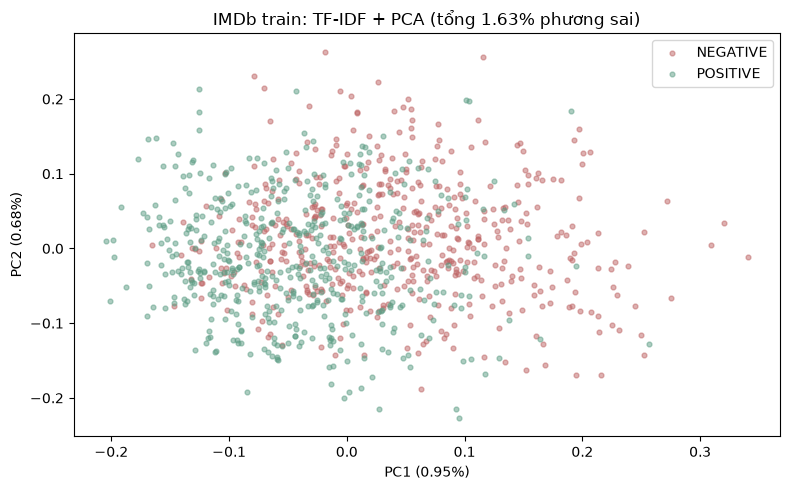

Số review cho PCA: 1000 | Số chiều TF-IDF: 1000


In [6]:
pca_per_class = min(500, int(train_df["label"].value_counts().min()))
pca_df = (train_df.groupby("label", group_keys=False)
          .sample(n=pca_per_class, random_state=CONFIG["seed"])
          .sample(frac=1, random_state=CONFIG["seed"]).reset_index(drop=True))
vectorizer = TfidfVectorizer(max_features=1000, min_df=2, max_df=.95,
                             stop_words="english", sublinear_tf=True)
X_tfidf = vectorizer.fit_transform(pca_df["text"])
# Giới hạn mẫu khiến phép chuyển sang dense có kích thước nhỏ (<= 1000 x 1000).
pca_model = PCA(n_components=2, svd_solver="randomized", random_state=CONFIG["seed"])
X_pca = pca_model.fit_transform(X_tfidf.toarray())
coords = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1],
                       "label": pca_df["label"].to_numpy()})
coords["label_name"] = coords["label"].map({0:"NEGATIVE",1:"POSITIVE"})
coords.to_csv(OUTPUT_DIR / "pca_coordinates.csv", index=False)
variance = pca_model.explained_variance_ratio_.tolist()
save_json(OUTPUT_DIR / "pca_metadata.json", {
    "n_samples": len(coords), "n_features": int(X_tfidf.shape[1]),
    "variance_ratio": variance, "total_variance_ratio": float(sum(variance))})

fig, ax = plt.subplots(figsize=(8, 5))
for name, color in [("NEGATIVE", "#be6464"), ("POSITIVE", "#5c9d84")]:
    subset = coords.loc[coords["label_name"].eq(name)]
    ax.scatter(subset["PC1"], subset["PC2"], s=12, alpha=.5, label=name, color=color)
ax.set(xlabel=f"PC1 ({variance[0]:.2%})", ylabel=f"PC2 ({variance[1]:.2%})",
       title=f"IMDb train: TF-IDF + PCA (tổng {sum(variance):.2%} phương sai)")
ax.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "pca_visualization.png", dpi=160)
plt.show()
print("Số review cho PCA:", len(coords), "| Số chiều TF-IDF:", X_tfidf.shape[1])

# PHẦN B — EXERCISE 1: SENTIMENT ANALYSIS

Theo đề bài: cài `transformers` → tải sentiment model đã fine-tune trên Hugging Face Hub → tokenization câu mẫu → dự đoán sentiment. **Không train mới trong Exercise 1.**

## B.1 — Tải pretrained model và tokenizer

Dùng checkpoint `distilbert/distilbert-base-uncased-finetuned-sst-2-english`. Nếu dùng lần đầu cần Internet. Model được chuyển sang GPU nếu có, ngược lại dùng CPU.

In [7]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

EX1_MODEL = CONFIG["exercise1_model"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
try:
    ex1_tokenizer = AutoTokenizer.from_pretrained(EX1_MODEL)
    ex1_model = AutoModelForSequenceClassification.from_pretrained(EX1_MODEL)
except Exception as exc:
    raise RuntimeError(
        f"Không tải được pretrained model Exercise 1: {EX1_MODEL}. "
        "Kiểm tra Internet / Hugging Face Hub."
    ) from exc
ex1_model.to(device).eval()
print("Model:", EX1_MODEL)
print("Thiết bị:", device)
print("id2label:", ex1_model.config.id2label)

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


Model: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Thiết bị: cpu
id2label: {0: 'NEGATIVE', 1: 'POSITIVE'}


d:\lab\Lab3_DL_Group4-main\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Hoang Thien (Sora)\.cache\huggingface\hub\models--distilbert--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


## B.2 — Tokenize câu ví dụ

Quan sát `input_ids`, `attention_mask` và chuỗi token để giải thích vai trò tokenizer và token đặc biệt `[CLS]`, `[SEP]`.

In [8]:
SAMPLE_TEXT = "I love this movie. The acting is amazing!"
tokenized_sample = ex1_tokenizer(SAMPLE_TEXT, return_tensors="pt", truncation=True)
print("Câu mẫu:", SAMPLE_TEXT)
print("Tokens:", ex1_tokenizer.convert_ids_to_tokens(tokenized_sample["input_ids"][0]))
print("input_ids:", tokenized_sample["input_ids"][0].tolist())
print("attention_mask:", tokenized_sample["attention_mask"][0].tolist())
print("Shape:", tuple(tokenized_sample["input_ids"].shape))

Câu mẫu: I love this movie. The acting is amazing!
Tokens: ['[CLS]', 'i', 'love', 'this', 'movie', '.', 'the', 'acting', 'is', 'amazing', '!', '[SEP]']
input_ids: [101, 1045, 2293, 2023, 3185, 1012, 1996, 3772, 2003, 6429, 999, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Shape: (1, 12)


## B.3 — Suy luận và lưu dự đoán cảm xúc

`softmax(logits)` chuyển logits thành phân phối xác suất; `argmax` xác định lớp dự đoán. Score là xác suất đầu ra của mô hình, không nhất thiết là độ tin cậy đã được hiệu chuẩn.

In [9]:
example_texts = [
    SAMPLE_TEXT,
    "This movie is extremely boring and disappointing.",
    "The visuals were good, although the story was weak.",
]
ex1_inputs = ex1_tokenizer(example_texts, padding=True, truncation=True,
                           max_length=256, return_tensors="pt")
ex1_inputs = {name: tensor.to(device) for name, tensor in ex1_inputs.items()}
with torch.no_grad():
    probs = torch.softmax(ex1_model(**ex1_inputs).logits, dim=-1).cpu().numpy()
pred_ids = probs.argmax(axis=1)
ex1_results = pd.DataFrame({
    "text": example_texts,
    "predicted_label": [ex1_model.config.id2label[int(i)] for i in pred_ids],
    "score": [round(float(probs[k, i]), 6) for k, i in enumerate(pred_ids)],
})
display(ex1_results)
ex1_results.to_csv(OUTPUT_DIR / "exercise1_predictions.csv", index=False, encoding="utf-8-sig")

# Giải phóng mô hình Exercise 1 trước khi tạo model train của Exercise 2.
del ex1_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

,text,predicted_label,score
0,I love this movie. The acting is amazing!,POSITIVE,0.999881
1,This movie is extremely boring and disappointing.,NEGATIVE,0.999794
2,"The visuals were good, although the story was ...",POSITIVE,0.999764


# PHẦN C — EXERCISE 2: FINE-TUNING BINARY TEXT CLASSIFICATION

Các bước: chia dữ liệu nhị phân → tải DistilBERT pretrained và tokenizer → tokenize → khai báo `TrainingArguments` → tạo `Trainer` → fine-tune → đánh giá test → lưu và nạp model.

**Quy tắc:** Validation dùng để chọn checkpoint theo `eval_loss` thấp nhất. Test chỉ dùng **sau khi** đã chọn checkpoint. Không dùng PCA làm input cho DistilBERT.

## C.1 — Chia train/validation/test

Phần C **dùng lại `train_df` và `test_df` từ Phần A**, không gọi `load_dataset` lần thứ hai. Train và validation được phân tầng từ split train IMDb; test lấy từ split test IMDb. Dữ liệu trùng được loại bỏ để hạn chế rò rỉ thông tin.

In [10]:
def balanced_sample(frame, size, seed):
    """Lấy đúng size review, số lượng lớp 0 và 1 bằng nhau."""
    if size <= 0 or size % 2:
        raise ValueError("train_size/validation_size/test_size phải là số chẵn dương")
    counts = frame["label"].value_counts()
    if any(int(counts.get(cls, 0)) < size // 2 for cls in (0, 1)):
        raise ValueError(f"Không đủ dữ liệu mỗi lớp để lấy {size} review; counts={counts.to_dict()}")
    return (frame.groupby("label", group_keys=False)
            .sample(n=size//2, random_state=seed)
            .sample(frac=1, random_state=seed).reset_index(drop=True))

# Chia trên tập train gốc đã làm sạch; tránh rò rỉ giữa hai tập.
train_pool, val_pool = train_test_split(
    train_df, test_size=0.1, stratify=train_df["label"],
    random_state=CONFIG["seed"])
train_selected = balanced_sample(train_pool, CONFIG["train_size"], CONFIG["seed"])
val_selected = balanced_sample(val_pool, CONFIG["validation_size"], CONFIG["seed"] + 1)

# Bỏ các văn bản trùng train/validation trong test (nếu có).
known_texts = set(train_selected["text"]) | set(val_selected["text"])
test_candidates = test_df.loc[~test_df["text"].isin(known_texts)].copy()
test_selected = balanced_sample(test_candidates, CONFIG["test_size"], CONFIG["seed"] + 2)
assert set(train_selected["text"]).isdisjoint(val_selected["text"])
assert set(train_selected["text"]).isdisjoint(test_selected["text"])
assert set(val_selected["text"]).isdisjoint(test_selected["text"])

split_summary = {}
for name, frame in [("train", train_selected), ("validation", val_selected), ("test", test_selected)]:
    split_summary[name] = {"size": len(frame), "label_count": {
        str(k): int(v) for k, v in frame["label"].value_counts().sort_index().items()}}
print("Số mẫu và tỷ lệ nhãn sau chia:")
display(pd.DataFrame([{"split": k, "size": v["size"], **v["label_count"]}
                      for k, v in split_summary.items()]))
save_json(OUTPUT_DIR / "data_summary.json", split_summary)

# Chỉ giữ hai cột cần thiết trong datasets để tránh lỗi ở data collator.
train_set = Dataset.from_pandas(train_selected[["text", "label"]], preserve_index=False)
val_set = Dataset.from_pandas(val_selected[["text", "label"]], preserve_index=False)
test_set = Dataset.from_pandas(test_selected[["text", "label"]], preserve_index=False)

Số mẫu và tỷ lệ nhãn sau chia:


,split,size,0,1
0,train,1000,500,500
1,validation,200,100,100
2,test,200,100,100


## C.2 — Tải tokenizer và mô hình pretrained để fine-tune

Model base `distilbert-base-uncased` chưa có classification head đã huấn luyện cho IMDb, vì vậy tầng phân loại nhị phân được khởi tạo mới; đây là hành vi bình thường. Đếm tổng số tham số và ghi lại cấu hình.

In [11]:
BASE_CHECKPOINT = CONFIG["model"]
label_names = {0: "NEGATIVE", 1: "POSITIVE"}
label_to_id = {value: key for key, value in label_names.items()}
ex2_tokenizer = AutoTokenizer.from_pretrained(BASE_CHECKPOINT)
ex2_model = AutoModelForSequenceClassification.from_pretrained(
    BASE_CHECKPOINT, num_labels=2, id2label=label_names, label2id=label_to_id)
print("Model:", ex2_model.config.model_type)
print("Số lớp:", ex2_model.config.num_labels)
print("Tổng tham số:", f"{sum(p.numel() for p in ex2_model.parameters()):,}")
print("Nhãn:", ex2_model.config.id2label)

d:\lab\Lab3_DL_Group4-main\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Hoang Thien (Sora)\.cache\huggingface\hub\models--distilbert--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling

Model: distilbert
Số lớp: 2
Tổng tham số: 66,955,010
Nhãn: {0: 'NEGATIVE', 1: 'POSITIVE'}


## C.3 — Tokenization và data collator

- `truncation=True`, `max_length=256` để giới hạn số token.
- `DataCollatorWithPadding` padding động trong mỗi batch.
- Huấn luyện dùng văn bản đã tokenized; các cột `text` được loại bỏ ở đầu vào Trainer nhưng vẫn giữ ở `test_selected` để phân tích lỗi.

In [12]:
from transformers import DataCollatorWithPadding

def tokenize_batch(batch):
    return ex2_tokenizer(batch["text"], truncation=True,
                         max_length=CONFIG["max_length"])

train_tok = train_set.map(tokenize_batch, batched=True, remove_columns=["text"])
val_tok = val_set.map(tokenize_batch, batched=True, remove_columns=["text"])
test_tok = test_set.map(tokenize_batch, batched=True, remove_columns=["text"])
collator = DataCollatorWithPadding(tokenizer=ex2_tokenizer)
lengths = [len(ids) for ids in train_tok["input_ids"]]
print("Số mẫu sau tokenize:", len(train_tok), len(val_tok), len(test_tok))
print("input_ids ví dụ:", train_tok[0]["input_ids"][:20])
print("attention_mask:", train_tok[0]["attention_mask"][:20])
print("Độ dài token trung bình:", round(float(np.mean(lengths)), 2),
      "| Dài nhất:", max(lengths))

Map: 100%|██████████| 200/200 [00:00<00:00, 4342.45 examples/s]

Số mẫu sau tokenize: 1000 200 200
input_ids ví dụ: [101, 2307, 1010, 2307, 1010, 2307, 999, 2008, 2003, 2035, 1045, 2064, 2360, 2055, 2008, 3185, 1010, 2021, 10047, 18939]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Độ dài token trung bình: 201.29 | Dài nhất: 256


## C.4 — TrainingArguments

Dùng cross-entropy mặc định của `AutoModelForSequenceClassification`, optimizer AdamW, learning rate `2e-5`, weight decay `0.01`. Checkpoint được lưu sau mỗi epoch và chọn theo **validation loss thấp nhất**.

Code hỗ trợ cả các phiên bản Transformers có tên tham số `eval_strategy` hoặc `evaluation_strategy`.

In [13]:
training_args = None
if RUN_TRAIN:
    from transformers import TrainingArguments
    training_kwargs = dict(
        output_dir=str(OUTPUT_DIR / "checkpoints"),
        seed=CONFIG["seed"], data_seed=CONFIG["seed"],
        num_train_epochs=CONFIG["epochs"],
        per_device_train_batch_size=CONFIG["batch_size"],
        per_device_eval_batch_size=CONFIG["batch_size"],
        learning_rate=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"],
        logging_strategy="steps", logging_steps=max(1, math.ceil(len(train_tok)/CONFIG["batch_size"]/4)),
        save_strategy="epoch", load_best_model_at_end=True,
        metric_for_best_model="eval_loss", greater_is_better=False,
        save_total_limit=2, report_to="none", optim="adamw_torch",
    )
    sig = inspect.signature(TrainingArguments.__init__).parameters
    strategy_key = "eval_strategy" if "eval_strategy" in sig else "evaluation_strategy"
    training_kwargs[strategy_key] = "epoch"
    training_args = TrainingArguments(**training_kwargs)
    print("Thiết bị huấn luyện:", training_args.device)
    print("Số epoch:", training_args.num_train_epochs)
    print("Batch size:", training_args.per_device_train_batch_size)
    print("Learning rate:", training_args.learning_rate)
else:
    print("RUN_TRAIN=False: không khởi tạo TrainingArguments.")

Thiết bị huấn luyện: cpu
Số epoch: 2
Batch size: 8
Learning rate: 2e-05


## C.5 — Tạo Trainer, định nghĩa metric và fine-tune

`Trainer` tính forward loss, backpropagation và cập nhật trọng số. `compute_metrics` tính Accuracy, Precision, Recall và F1 cho nhãn `POSITIVE`. Đây là hàm **nằm trong notebook**, không còn import `src.evaluate` nên tránh lỗi import sai.

In [14]:
def classification_scores(y_true, y_pred):
    """Các chỉ số của bài toán phân loại nhị phân, Positive là nhãn 1."""
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0)
    return {"accuracy": float(accuracy_score(y_true, y_pred)),
            "precision_positive": float(p), "recall_positive": float(r),
            "f1_positive": float(f1)}


def compute_metrics(eval_prediction):
    logits = eval_prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    predictions = np.asarray(logits).argmax(axis=-1)
    return classification_scores(eval_prediction.label_ids, predictions)

trainer = None
train_result = None
training_started_utc = None
if RUN_TRAIN:
    from transformers import Trainer
    trainer_kwargs = dict(
        model=ex2_model, args=training_args,
        train_dataset=train_tok, eval_dataset=val_tok,
        data_collator=collator, compute_metrics=compute_metrics,
    )
    trainer_sig = inspect.signature(Trainer.__init__).parameters
    if "processing_class" in trainer_sig:
        trainer_kwargs["processing_class"] = ex2_tokenizer
    elif "tokenizer" in trainer_sig:
        trainer_kwargs["tokenizer"] = ex2_tokenizer
    trainer = Trainer(**trainer_kwargs)
    training_started_utc = datetime.now(timezone.utc).isoformat()
    print("Bắt đầu fine-tuning; đây là lượt train mới.")
    train_result = trainer.train()
    trainer.save_state()
    print("Training loss cuối:", round(float(train_result.training_loss), 6))
    print("Checkpoint tốt nhất:", trainer.state.best_model_checkpoint)
    print("Best validation loss:", trainer.state.best_metric)
else:
    print("Chưa fine-tune: RUN_TRAIN=False.")

Bắt đầu fine-tuning; đây là lượt train mới.


d:\lab\Lab3_DL_Group4-main\.venv\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss,Accuracy,Precision Positive,Recall Positive,F1 Positive
1,0.451600,0.341547,0.865000,0.801653,0.970000,0.877828
2,0.183100,0.264297,0.905000,0.893204,0.920000,0.906404


d:\lab\Lab3_DL_Group4-main\.venv\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Training loss cuối: 0.389922
Checkpoint tốt nhất: c:\Users\Hoang Thien (Sora)\Downloads\outputs\practice3_20261113_163141\checkpoints\checkpoint-250
Best validation loss: 0.26429739594459534


## C.6 — Lịch sử huấn luyện và biểu đồ loss

Xuất `history.csv`, `loss_curves.png`. Loss train và validation được tách theo bản ghi thực tế từ `trainer.state.log_history`; hai biểu đồ không được tự tạo số liệu.

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_precision_positive,eval_recall_positive,eval_f1_positive,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.6828,1.962395,0.000018,0.256,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.6095,3.906661,0.000015,0.512,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.4516,12.502281,0.000012,0.768,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,1.000,125,0.341547,0.865,0.801653,0.97,0.877828,20.1705,9.915,1.239,NaN,NaN,NaN,NaN,NaN
4,0.4009,10.136840,0.000010,1.024,128,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.2980,2.496487,0.000007,1.280,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.1952,1.750463,0.000005,1.536,192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0.1831,2.081523,0.000002,1.792,224,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,2.000,250,0.264297,0.905,0.893204,0.92,0.906404,18.4827,10.821,1.353,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,2.000,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,853.5046,2.343,0.293,1.319706e+14,0.389922


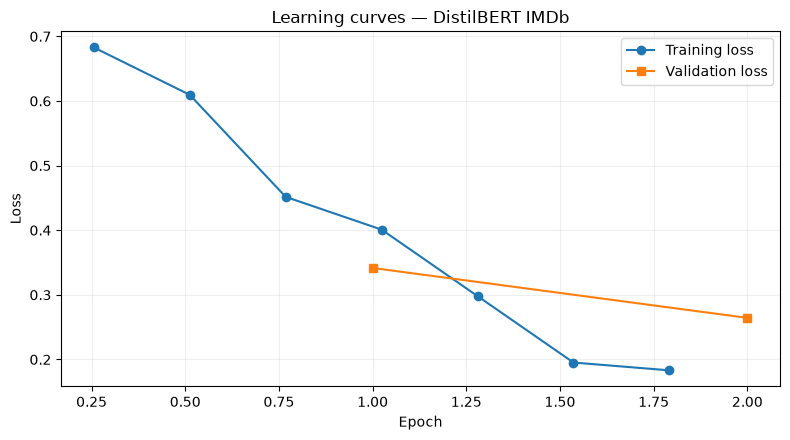

In [15]:
if trainer is not None and train_result is not None:
    history = pd.DataFrame(trainer.state.log_history)
    history.to_csv(OUTPUT_DIR / "history.csv", index=False)
    display(history.tail(12))

    fig, ax = plt.subplots(figsize=(8, 4.5))
    if {"epoch", "loss"}.issubset(history.columns):
        t = history.dropna(subset=["epoch", "loss"])
        if not t.empty:
            ax.plot(t["epoch"], t["loss"], "o-", label="Training loss")
    if {"epoch", "eval_loss"}.issubset(history.columns):
        v = history.dropna(subset=["epoch", "eval_loss"])
        if not v.empty:
            ax.plot(v["epoch"], v["eval_loss"], "s-", label="Validation loss")
    ax.set(xlabel="Epoch", ylabel="Loss", title="Learning curves — DistilBERT IMDb")
    ax.legend()
    ax.grid(alpha=.2)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "loss_curves.png", dpi=160)
    plt.show()
else:
    print("Chưa có lịch sử fine-tuning mới (RUN_TRAIN=False).")

## C.7 — Đánh giá trên test (chỉ sau khi đã train)

`trainer.predict(test_tok)` sử dụng checkpoint tốt nhất đã nạp lại cuối quá trình huấn luyện. Tính Accuracy/Precision/Recall/F1, confusion matrix, classification report, lưu kết quả từng review và `test_metrics.json`.

**Không lấy con số test cũ để giả lập kết quả của lần train này.**

d:\lab\Lab3_DL_Group4-main\.venv\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Kết quả đánh giá test của lần train này:


,accuracy,precision_positive,recall_positive,f1_positive,test_samples,best_val_loss,best_checkpoint
0,0.865,0.861386,0.87,0.865672,200,0.264297,c:\Users\Hoang Thien (Sora)\Downloads\outputs\...


              precision    recall  f1-score   support

    NEGATIVE       0.87      0.86      0.86       100
    POSITIVE       0.86      0.87      0.87       100

    accuracy                           0.86       200
   macro avg       0.87      0.86      0.86       200
weighted avg       0.87      0.86      0.86       200



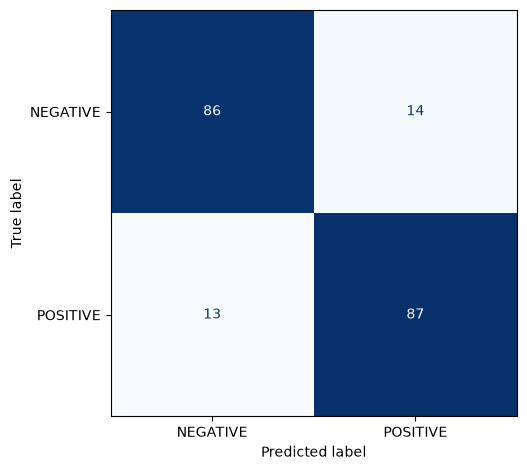

In [16]:
new_metrics = None
if trainer is not None and train_result is not None:
    test_prediction = trainer.predict(test_tok)
    logits = test_prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    predictions = np.asarray(logits).argmax(axis=-1).astype(int)
    actual = test_selected["label"].to_numpy().astype(int)
    new_metrics = classification_scores(actual, predictions)
    new_metrics.update(test_samples=len(actual),
                       best_val_loss=(None if trainer.state.best_metric is None
                                      else float(trainer.state.best_metric)),
                       best_checkpoint=trainer.state.best_model_checkpoint)
    save_json(OUTPUT_DIR / "test_metrics.json", new_metrics)
    print("Kết quả đánh giá test của lần train này:")
    display(pd.DataFrame([new_metrics]))

    predictions_df = test_selected[["text", "label"]].copy().reset_index(drop=True)
    predictions_df = predictions_df.rename(columns={"label": "true_label"})
    predictions_df["predicted_label"] = predictions
    predictions_df["correct"] = (predictions_df["true_label"] == predictions_df["predicted_label"]).astype(int)
    predictions_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig")

    report = classification_report(actual, predictions, labels=[0, 1],
                                   target_names=["NEGATIVE", "POSITIVE"], zero_division=0)
    (OUTPUT_DIR / "classification_report.txt").write_text(report, encoding="utf-8")
    print(report)
    cm = confusion_matrix(actual, predictions, labels=[0, 1])
    pd.DataFrame(cm, index=["NEGATIVE", "POSITIVE"],
                 columns=["NEGATIVE", "POSITIVE"]).to_csv(OUTPUT_DIR / "confusion_matrix.csv")
    fig, ax = plt.subplots(figsize=(5.6, 4.8))
    ConfusionMatrixDisplay(cm, display_labels=["NEGATIVE", "POSITIVE"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=160)
    plt.show()
else:
    print("Chưa có kết quả test mới vì chưa fine-tune.")

## C.8 — Lưu và nạp lại mô hình

Với `load_best_model_at_end=True`, sau khi train xong Trainer đã chứa trọng số của checkpoint có `eval_loss` nhỏ nhất. Lưu model và tokenizer vào `best_model/`, sau đó tải lại để thử dự đoán một review mới.

In [17]:
if trainer is not None and train_result is not None:
    best_model_dir = OUTPUT_DIR / "best_model"
    trainer.save_model(str(best_model_dir))
    ex2_tokenizer.save_pretrained(str(best_model_dir))
    run_info = {
        "started_at_utc": training_started_utc,
        "finished_at_utc": datetime.now(timezone.utc).isoformat(),
        "best_checkpoint": trainer.state.best_model_checkpoint,
        "best_val_loss": (None if trainer.state.best_metric is None
                          else float(trainer.state.best_metric)),
        "model_path": str(best_model_dir), "train_samples": len(train_tok),
        "validation_samples": len(val_tok), "test_samples": len(test_tok),
        "config": CONFIG,
    }
    save_json(OUTPUT_DIR / "run_info.json", run_info)
    print("Đã lưu:", best_model_dir)

    # Sau khi lưu, chuyển model đã train về CPU để giảm bộ nhớ GPU.
    # Giữ biến trainer để người học có thể xem kết quả hoặc chạy lại cell.
    if torch.cuda.is_available():
        trainer.model.to("cpu")
        torch.cuda.empty_cache()
    gc.collect()
    saved_tokenizer = AutoTokenizer.from_pretrained(best_model_dir)
    saved_model = AutoModelForSequenceClassification.from_pretrained(best_model_dir).eval()
    sentence = "The story was fascinating and the acting was excellent."
    inputs = saved_tokenizer(sentence, return_tensors="pt", truncation=True)
    with torch.no_grad():
        p = torch.softmax(saved_model(**inputs).logits, dim=-1)[0]
    predicted = int(p.argmax())
    print("Dự đoán sau khi nạp lại:", saved_model.config.id2label[predicted],
          "| Score:", round(float(p[predicted]), 4))
else:
    print("Chưa lưu checkpoint: RUN_TRAIN=False.")

Đã lưu: c:\Users\Hoang Thien (Sora)\Downloads\outputs\practice3_20261113_163141\best_model
Dự đoán sau khi nạp lại: POSITIVE | Score: 0.9648


## C.9 — Phân tích một số review dự đoán sai

Xem những mẫu sai để thảo luận ảnh hưởng của phủ định, review pha trộn tích cực/tiêu cực, và việc cắt ngắn ở `max_length=256`. Đây là phân tích định tính, không đủ để khẳng định nguyên nhân sai của từng review.

In [18]:
pred_path = OUTPUT_DIR / "test_predictions.csv"
if pred_path.is_file() and new_metrics is not None:
    errors = pd.read_csv(pred_path)
    errors = errors.loc[errors["correct"].eq(0)].copy()
    print("Số review dự đoán sai:", len(errors))
    if len(errors):
        display(errors.assign(text=errors["text"].str.slice(0, 240)).head(8))
else:
    print("Chưa có test_predictions.csv mới nên chưa thể phân tích review dự đoán sai.")

Số review dự đoán sai: 27


,text,true_label,predicted_label,correct
0,"Thorn-BMI is out of business, before they stop...",1,0,0
12,"If you have a chance, see this Russian(how sho...",1,0,0
20,In relative terms having watched a lot of disg...,1,0,0
23,Dreamy young Ashton Kutcher (as Tom Stansfield...,0,1,0
24,My mother forced me to watch this movie with h...,0,1,0
28,I was plagued by nightmares involving Sesame S...,1,0,0
32,The problem with this series is that it is too...,1,0,0
43,The most famous thing about this movie is that...,0,1,0


# PHẦN D — Tổng kết và kiểm tra file đầu ra

Bảng bên dưới chỉ xác nhận file của **lần chạy notebook hiện tại**, không đọc CSV hoặc số liệu cũ. Với `RUN_TRAIN=False` những file checkpoint/metrics sẽ không được tạo, đây là kết quả đúng với chế độ đã chọn.

In [19]:
expected = [
    "config.json", "eda_quality.json", "eda_class_length.png",
    "pca_metadata.json", "pca_coordinates.csv", "pca_visualization.png",
    "exercise1_predictions.csv", "data_summary.json",
    "history.csv", "loss_curves.png", "test_metrics.json", "test_predictions.csv",
    "confusion_matrix.png", "classification_report.txt", "run_info.json",
]
file_status = pd.DataFrame([{"file": name, "exists": (OUTPUT_DIR / name).is_file()}
                            for name in expected])
display(file_status)
print("Checkpoint đã lưu:", (OUTPUT_DIR / "best_model" / "config.json").is_file())
print("RUN_TRAIN:", RUN_TRAIN, "| QUICK_TEST:", QUICK_TEST)
print("Kết quả lưu ở:", OUTPUT_DIR)
if RUN_TRAIN and new_metrics is not None:
    print("TEST ACCURACY (lượt chạy này):", f"{new_metrics['accuracy']:.2%}")
elif not RUN_TRAIN:
    print("Chưa huấn luyện theo lựa chọn RUN_TRAIN=False.")
else:
    print("Chưa có kết quả train/test mới; kiểm tra các cell trước khi nộp.")

,file,exists
0,config.json,True
1,eda_quality.json,True
2,eda_class_length.png,True
3,pca_metadata.json,True
4,pca_coordinates.csv,True
5,pca_visualization.png,True
6,exercise1_predictions.csv,True
7,data_summary.json,True
8,history.csv,True
9,loss_curves.png,True


Checkpoint đã lưu: True
RUN_TRAIN: True | QUICK_TEST: False
Kết quả lưu ở: c:\Users\Hoang Thien (Sora)\Downloads\outputs\practice3_20261113_163141
TEST ACCURACY (lượt chạy này): 86.50%
